In [1]:
# Cell 1 — Mount Drive, paths, imports
from google.colab import drive
drive.mount('/content/drive')

import sys, json, importlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RAW_DIR     = Path("/content/drive/MyDrive/CMAPSSData")
PROJECT_DIR = Path("/content/drive/MyDrive/Predictive_Maintenance_RUL")
FD = "FD001"
PROC_DIR = PROJECT_DIR / "data" / "processed" / FD
PREP_DIR = PROJECT_DIR / "models" / FD / "preprocessing"
FIG_DIR  = PROJECT_DIR / "reports" / "figures" / FD
FE_REPORT = PROJECT_DIR / "reports" / "feature_engineering" / FD
FE_REPORT.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(PROJECT_DIR))
sns.set_theme(style="whitegrid")
SEED = 42
print("Ready")

Mounted at /content/drive
Ready


In [2]:
%%writefile /content/drive/MyDrive/Predictive_Maintenance_RUL/src/feature_engineering.py
"""
feature_engineering.py — Leakage-free (causal) features for C-MAPSS.

Why this file exists: a single sensor reading is noisy; the *recent history* of an engine
carries the degradation signal. Every feature here at cycle t uses ONLY cycles <= t of the
SAME engine, so it can be computed identically in training, validation, test and the API.
Nothing in this file is fitted, so it cannot leak validation/test information.
"""
import numpy as np
import pandas as pd


# ----------------------------------------------------------------------------- tabular features
def add_rolling_features(df: pd.DataFrame, base_cols, window: int) -> pd.DataFrame:
    """For each base column add, per engine, over the last `window` cycles (current included):
         <col>_mean_w   rolling mean          (smooths noise)
         <col>_std_w    rolling std           (local volatility)
         <col>_slope_w  rolling linear slope  (direction + speed of degradation, units per cycle)
    At an engine's first cycles the window is shorter (min_periods=1); std/slope that are
    undefined there (only one point) are set to 0 = 'no variation observed yet'."""
    if not df.index.is_unique:
        raise ValueError("DataFrame index must be unique")
    df = df.sort_values(["engine_id", "cycle"])
    eng = df["engine_id"]

    def rmean(s):   # rolling mean of a series, restarted for every engine
        return s.groupby(eng).transform(lambda x: x.rolling(window, min_periods=1).mean())

    t = df["cycle"].astype(float)
    t_mean = rmean(t)
    var_t = rmean(t * t) - t_mean ** 2           # variance of cycle numbers inside the window

    new_cols = {}
    for c in base_cols:
        x = df[c].astype(float)
        x_mean = rmean(x)
        x_std = x.groupby(eng).transform(lambda s: s.rolling(window, min_periods=1).std())
        slope = (rmean(x * t) - x_mean * t_mean) / var_t.where(var_t > 1e-12)   # least-squares slope
        new_cols[f"{c}_mean_{window}"] = x_mean
        new_cols[f"{c}_std_{window}"] = x_std.fillna(0.0)
        new_cols[f"{c}_slope_{window}"] = slope.fillna(0.0)
    return pd.concat([df, pd.DataFrame(new_cols, index=df.index)], axis=1)


def tabular_feature_names(base_cols, window: int, include_cycle: bool):
    """Exact, fixed feature ORDER for the traditional models (LR / RF / XGBoost)."""
    names = list(base_cols)
    if window:
        for c in base_cols:
            names += [f"{c}_mean_{window}", f"{c}_std_{window}", f"{c}_slope_{window}"]
    if include_cycle:
        names.append("cycle")
    return names


def build_tabular(df_scaled: pd.DataFrame, base_cols, window: int, include_cycle: bool):
    """Return (feature_frame_with_ids, ordered_feature_names)."""
    out = add_rolling_features(df_scaled, base_cols, window) if window else df_scaled.copy()
    return out, tabular_feature_names(base_cols, window, include_cycle)


def rows_at(feature_df: pd.DataFrame, points: pd.DataFrame) -> pd.DataFrame:
    """Pick the feature row at each (engine_id, cut_cycle) in `points`, keeping the order of `points`."""
    out = points[["engine_id", "cut_cycle"]].merge(
        feature_df, left_on=["engine_id", "cut_cycle"], right_on=["engine_id", "cycle"], how="left")
    if out["cycle"].isna().any():
        raise ValueError("Some requested (engine_id, cycle) points do not exist in the data.")
    return out


# ----------------------------------------------------------------------------- LSTM sequences
def make_sequences(df_scaled: pd.DataFrame, feature_cols, seq_len: int, target: str = "RUL"):
    """All sliding windows of `seq_len` consecutive cycles inside each engine.
    Window ending at cycle t uses cycles t-seq_len+1 .. t; label = target at cycle t.
    Engines/cycles with fewer than seq_len cycles of history produce no window.
    Returns X [n, seq_len, n_features] float32, y [n], meta DataFrame[engine_id, end_cycle]."""
    X, y, meta = [], [], []
    for eid, g in df_scaled.sort_values(["engine_id", "cycle"]).groupby("engine_id"):
        arr = g[feature_cols].to_numpy(np.float32)
        cyc = g["cycle"].to_numpy()
        tgt = g[target].to_numpy(np.float32) if target in g else np.full(len(g), np.nan, np.float32)
        for end in range(seq_len - 1, len(g)):
            X.append(arr[end - seq_len + 1:end + 1])
            y.append(tgt[end])
            meta.append((int(eid), int(cyc[end])))
    X = np.stack(X) if X else np.empty((0, seq_len, len(feature_cols)), np.float32)
    return X, np.asarray(y, np.float32), pd.DataFrame(meta, columns=["engine_id", "end_cycle"])


def sequences_at(df_scaled: pd.DataFrame, feature_cols, seq_len: int, points: pd.DataFrame):
    """One window per (engine_id, cut_cycle) row of `points`, ending exactly at that cycle.
    Used for test-like validation, official test (last cycle) and API requests."""
    by_engine = {eid: g.sort_values("cycle") for eid, g in df_scaled.groupby("engine_id")}
    X = []
    for eid, cut in zip(points["engine_id"], points["cut_cycle"]):
        g = by_engine[eid]
        hist = g[g["cycle"] <= cut][feature_cols].to_numpy(np.float32)
        if len(hist) < seq_len:
            raise ValueError(f"Engine {eid} has only {len(hist)} cycles up to {cut}; need {seq_len}.")
        X.append(hist[-seq_len:])
    return np.stack(X)

Writing /content/drive/MyDrive/Predictive_Maintenance_RUL/src/feature_engineering.py


In [3]:
# Cell 3 — Load data + the SAVED Phase 3 pipeline (nothing is re-fitted here)
import src.data_loader as dl, src.preprocessing as pp, src.evaluation as ev, src.feature_engineering as fe
for m in (dl, pp, ev, fe):
    importlib.reload(m)

meta  = json.loads((PREP_DIR / "pipeline_metadata.json").read_text())
split = json.loads((PROC_DIR / "split.json").read_text())
cuts  = pd.read_csv(PROC_DIR / "val_cut_points.csv")
prep  = pp.CMAPSSPreprocessor.load(PREP_DIR)
CAP, B = meta["rul_cap"], prep.feature_cols

d = dl.load_dataset(FD, RAW_DIR)
full = pp.add_train_rul(d["train"], cap=CAP)                     # capped training target
tr = full[full.engine_id.isin(split["train_engine_ids"])].reset_index(drop=True)
va = full[full.engine_id.isin(split["val_engine_ids"])].reset_index(drop=True)
tr_s, va_s = prep.transform(tr), prep.transform(va)

print(f"Cap = {CAP} | base features = {len(B)} | train rows {len(tr_s)} | val rows {len(va_s)} | cut points {len(cuts)}")

Cap = 125 | base features = 14 | train rows 16390 | val rows 4241 | cut points 200


In [4]:
# Cell 4 — Correctness + causality tests
W = 10
f1 = fe.add_rolling_features(va_s, B, W)

# 1) Causality: corrupt an engine's FUTURE (cycles > 100) → its features at cycles <= 100 must not change
eid = split["val_engine_ids"][0]
corrupted = va_s.copy()
corrupted.loc[(corrupted.engine_id == eid) & (corrupted.cycle > 100), B] += 50
f2 = fe.add_rolling_features(corrupted, B, W)
past = (f1.engine_id == eid) & (f1.cycle <= 100)
feat_cols = [c for c in f1.columns if c != "RUL"]
assert np.allclose(f1.loc[past, feat_cols].values, f2.loc[past, feat_cols].values)
print("✅ Causal: changing the future does not change past features")

# 2) First cycle of each engine: mean = value itself, std = slope = 0
first = f1.groupby("engine_id").head(1)
assert np.allclose(first[f"{B[0]}_mean_{W}"], first[B[0]]) and (first[f"{B[0]}_std_{W}"] == 0).all()
print("✅ Engine boundaries respected (window restarts per engine)")

# 3) Slope equals numpy's least-squares line fit
g = f1[f1.engine_id == eid].sort_values("cycle")
assert np.isclose(np.polyfit(g.cycle.values[40:50], g[B[0]].values[40:50], 1)[0], g[f"{B[0]}_slope_{W}"].values[49])
print("✅ Rolling slope matches np.polyfit")

✅ Causal: changing the future does not change past features
✅ Engine boundaries respected (window restarts per engine)
✅ Rolling slope matches np.polyfit


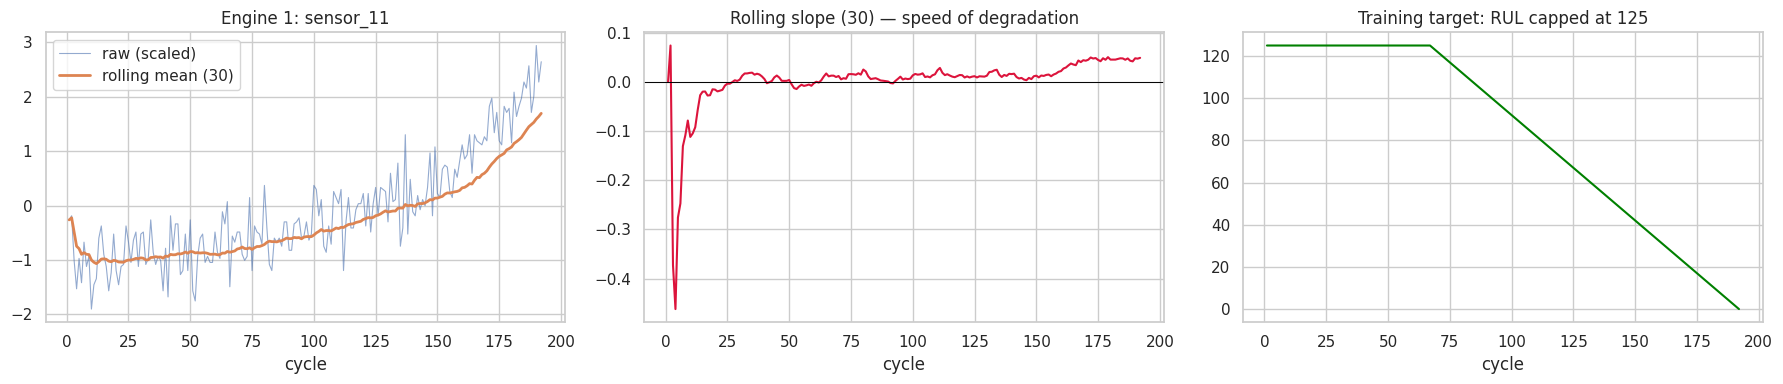

In [5]:
# Cell 5 — Raw vs engineered signal for one training engine
eng_id = split["train_engine_ids"][0]
g = fe.add_rolling_features(tr_s[tr_s.engine_id == eng_id], ["sensor_11"], 30)

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].plot(g.cycle, g.sensor_11, lw=0.8, alpha=0.6, label="raw (scaled)")
axes[0].plot(g.cycle, g.sensor_11_mean_30, lw=2, label="rolling mean (30)")
axes[0].set(title=f"Engine {eng_id}: sensor_11", xlabel="cycle"); axes[0].legend()
axes[1].plot(g.cycle, g.sensor_11_slope_30, color="crimson")
axes[1].axhline(0, color="black", lw=0.7)
axes[1].set(title="Rolling slope (30) — speed of degradation", xlabel="cycle")
axes[2].plot(g.cycle, g.RUL, color="green")
axes[2].set(title=f"Training target: RUL capped at {CAP}", xlabel="cycle")
fig.tight_layout(); fig.savefig(FIG_DIR / "12_engineered_features_example.png", dpi=150, bbox_inches="tight"); plt.show()

,window,cycle_feat,probe,n_features,RMSE_le125,MAE_le125,bias_le125,NASA_le125_per_pt,RMSE_all200
0,0,False,LR,14,21.51,17.94,7.68,10.86,42.27
1,0,False,RF,14,19.74,14.41,5.27,16.12,41.00
2,0,True,LR,15,21.22,17.15,5.64,9.39,42.26
3,0,True,RF,15,17.48,12.65,2.65,7.84,40.55
4,5,False,LR,56,21.05,17.83,8.14,9.58,42.22
5,5,False,RF,56,19.74,14.20,5.45,14.45,40.37
6,5,True,LR,57,20.80,16.95,6.05,8.59,42.23
7,5,True,RF,57,17.12,12.47,2.74,6.31,39.97
8,10,False,LR,56,21.14,17.87,8.09,9.93,42.18
9,10,False,RF,56,20.16,15.07,5.41,12.59,40.58


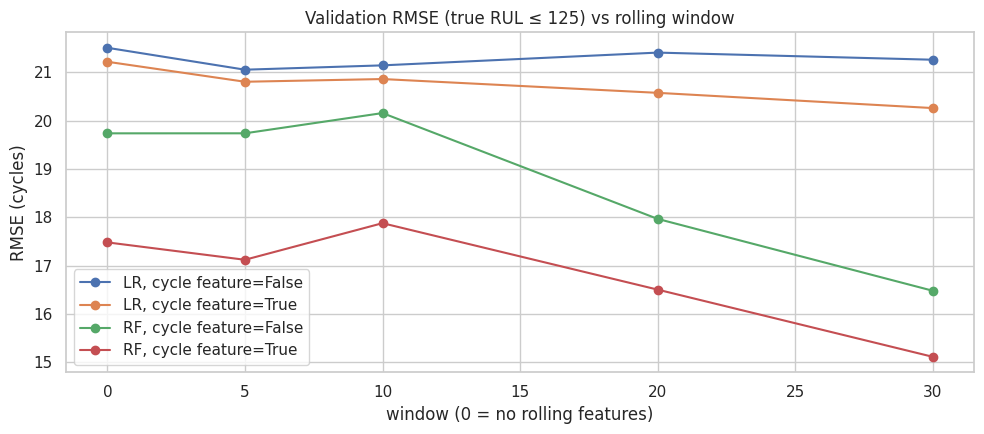

In [6]:
# Cell 6 — Window size + cycle feature, judged on the 200 test-like validation points
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

y_cut = cuts["true_rul"].values
m125 = y_cut <= 125
rows = []
for w in [0, 5, 10, 20, 30]:                      # 0 = current readings only
    trf, _ = fe.build_tabular(tr_s, B, w, include_cycle=False)
    vaf, _ = fe.build_tabular(va_s, B, w, include_cycle=False)
    Xc_all = fe.rows_at(vaf, cuts)
    for inc in [False, True]:
        names = fe.tabular_feature_names(B, w, inc)
        for probe, model in [("LR", LinearRegression()),
                             ("RF", RandomForestRegressor(n_estimators=100, min_samples_leaf=5,
                                                          n_jobs=-1, random_state=SEED))]:
            model.fit(trf[names], trf["RUL"])
            pred = np.clip(model.predict(Xc_all[names]), 0, None)
            rows.append({"window": w, "cycle_feat": inc, "probe": probe, "n_features": len(names),
                         "RMSE_le125": ev.rmse(y_cut[m125], pred[m125]),
                         "MAE_le125": ev.mae(y_cut[m125], pred[m125]),
                         "bias_le125": float(np.mean(pred[m125] - y_cut[m125])),
                         "NASA_le125_per_pt": ev.nasa_score(y_cut[m125], pred[m125]) / m125.sum(),
                         "RMSE_all200": ev.rmse(y_cut, pred)})

fe_results = pd.DataFrame(rows)
fe_results.to_csv(FE_REPORT / "window_experiment.csv", index=False)
display(fe_results.round(2))

fig, ax = plt.subplots(figsize=(10, 4.5))
for (probe, inc), sub in fe_results.groupby(["probe", "cycle_feat"]):
    ax.plot(sub.window, sub.RMSE_le125, marker="o", label=f"{probe}, cycle feature={inc}")
ax.set(title="Validation RMSE (true RUL ≤ 125) vs rolling window", xlabel="window (0 = no rolling features)",
       ylabel="RMSE (cycles)"); ax.legend()
fig.tight_layout(); fig.savefig(FIG_DIR / "13_window_experiment.png", dpi=150, bbox_inches="tight"); plt.show()

In [7]:
# Cell 7 — Chronological windows for the LSTM
SEQ_LEN = 30
X_tr, y_tr, m_tr = fe.make_sequences(tr_s, B, SEQ_LEN)
X_va, y_va, m_va = fe.make_sequences(va_s, B, SEQ_LEN)
X_cut = fe.sequences_at(va_s, B, SEQ_LEN, cuts)

print("Train windows:", X_tr.shape, "| Val windows:", X_va.shape, "| Cut-point windows:", X_cut.shape)
print("Test engines with fewer than", SEQ_LEN, "cycles:", int((d["test"].groupby("engine_id").cycle.max() < SEQ_LEN).sum()))

# Verify the first window really is engine's cycles 1..30, labelled with RUL at cycle 30
e0, c0 = m_tr.iloc[0]
raw = tr_s[tr_s.engine_id == e0].sort_values("cycle")
assert c0 == SEQ_LEN and np.allclose(X_tr[0], raw[B].values[:SEQ_LEN])
assert y_tr[0] == raw.RUL.values[SEQ_LEN - 1]
print(f"✅ Window 0 = engine {e0}, cycles 1–{c0}, label {y_tr[0]:.0f}")

Train windows: (14070, 30, 14) | Val windows: (3661, 30, 14) | Cut-point windows: (200, 30, 14)
Test engines with fewer than 30 cycles: 0
✅ Window 0 = engine 1, cycles 1–30, label 125


In [8]:
# Cell 8 — Freeze Phase 4 decisions; saved next to the preprocessing artifacts
WINDOW, INCLUDE_CYCLE = 30, True
tabular_names = fe.tabular_feature_names(B, WINDOW, INCLUDE_CYCLE)

feature_config = {
    "dataset": FD,
    "base_features": B,
    "tabular": {"window": WINDOW, "include_cycle": INCLUDE_CYCLE,
                "rolling_stats": ["mean", "std", "slope"], "min_periods": 1,
                "feature_order": tabular_names, "n_features": len(tabular_names)},
    "lstm": {"seq_len": SEQ_LEN, "features": B, "n_features": len(B),
             "label": "capped RUL at last cycle of window",
             "min_history_required": SEQ_LEN, "padding": "none (shorter histories rejected)"},
    "cycle_requirement": "cycle must count from the start of the engine's recorded operation (cycle 1)",
    "selection_evidence": "reports/feature_engineering/FD001/window_experiment.csv",
}
(PROJECT_DIR / "models" / FD / "feature_config.json").write_text(json.dumps(feature_config, indent=2))
print(f"✅ Saved feature_config.json — tabular: {len(tabular_names)} features, LSTM: {SEQ_LEN}×{len(B)}")
print("First 5:", tabular_names[:5], "... Last 3:", tabular_names[-3:])

✅ Saved feature_config.json — tabular: 57 features, LSTM: 30×14
First 5: ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8'] ... Last 3: ['sensor_21_std_30', 'sensor_21_slope_30', 'cycle']
